<a href="https://colab.research.google.com/github/Lorichag/VisIA/blob/main/Object_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Partie 3 : ajout de YOLO

In [1]:
!pip install -q ultralytics #installation de YOLO

Chargement de YOLO

In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Chargement du modèle YOLO11n
yolo_model = YOLO("yolo11n.pt")

print("YOLO11n est chargé !")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO11n est chargé !


On récupère une image

Saving rue.jpg to rue (2).jpg


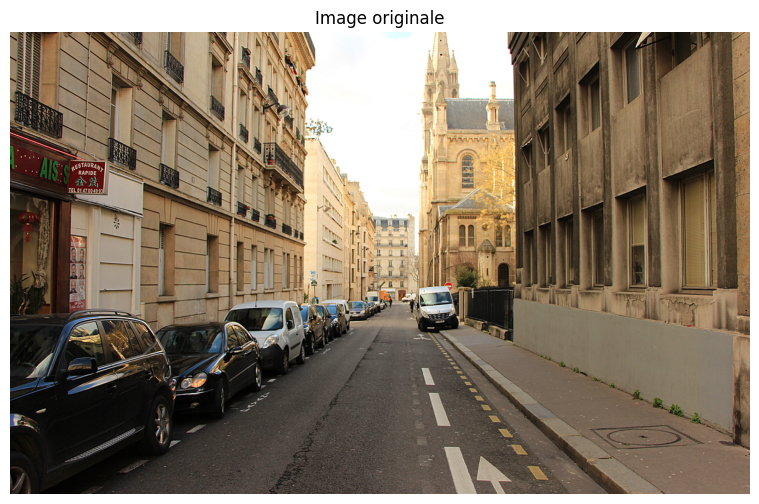

In [8]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.title("Image originale")
plt.axis("off")
plt.show()

On applique YOLO dessus

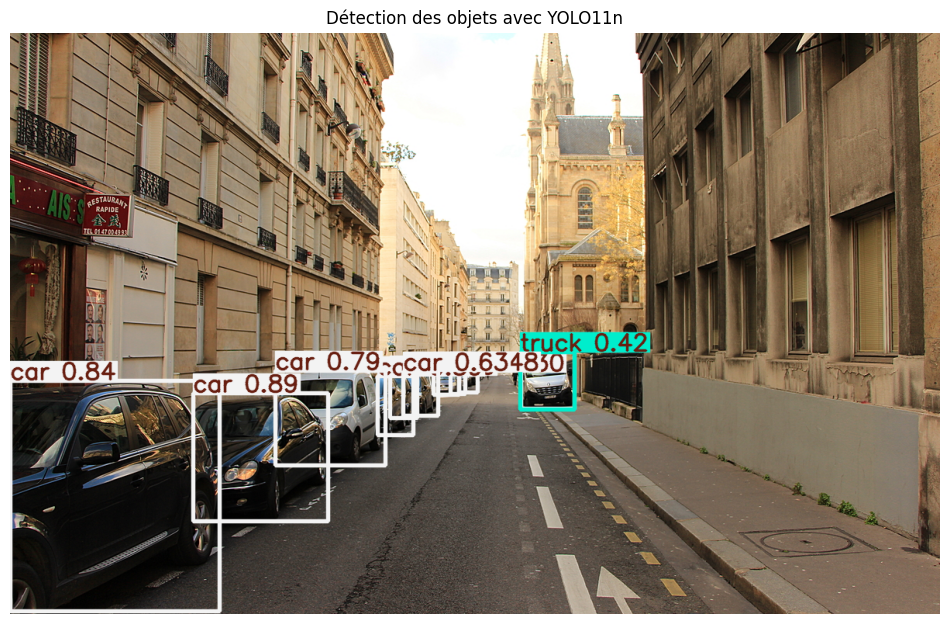

In [9]:
# Vérifier que l'image existe
assert image is not None, "Aucune image chargée"

# Détection des objets
results = yolo_model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Récupérer l'image avec les détections
annotated_image = results[0].plot()


# Affichage
plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("Détection des objets avec YOLO11n")
plt.show()

On récupère tous les objets détectés

In [10]:
result = results[0]

print("Nombre d'objets détectés :",
      len(result.boxes))

for box in result.boxes:

    # Coordonnées du rectangle
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    # Classe de l'objet
    class_id = int(box.cls[0])

    # Nom de l'objet
    class_name = result.names[class_id]

    # Score de confiance
    confidence = float(box.conf[0])

    print(
        f"Objet : {class_name} | "
        f"Confiance : {confidence:.2f} | "
        f"Position : ({int(x1)}, {int(y1)}, "
        f"{int(x2)}, {int(y2)})"
    )

Nombre d'objets détectés : 11
Objet : car | Confiance : 0.89 | Position : (236, 465, 410, 630)
Objet : car | Confiance : 0.84 | Position : (0, 449, 270, 746)
Objet : car | Confiance : 0.79 | Position : (342, 436, 484, 558)
Objet : car | Confiance : 0.63 | Position : (507, 437, 552, 494)
Objet : car | Confiance : 0.59 | Position : (474, 443, 520, 519)
Objet : car | Confiance : 0.48 | Position : (546, 437, 579, 467)
Objet : truck | Confiance : 0.42 | Position : (658, 412, 728, 486)
Objet : car | Confiance : 0.33 | Position : (659, 412, 728, 485)
Objet : car | Confiance : 0.30 | Position : (490, 442, 525, 497)
Objet : car | Confiance : 0.30 | Position : (579, 438, 603, 464)
Objet : car | Confiance : 0.27 | Position : (568, 437, 587, 466)


On ajoute la carte de profondeur

Si vous avez telecharger la carte de l'image

In [17]:
import numpy as np

from google.colab import files

uploaded = files.upload()

depth_map = np.load("depth_map.npy")

print("Carte de profondeur chargée !")
print("Dimensions :", depth_map.shape)

Saving depth_map.npy to depth_map.npy
Carte de profondeur chargée !
Dimensions : (750, 1200)


In [18]:
# IMPORTANT :
# depth_map doit correspondre exactement à l'image utilisée par YOLO.
# Si nécessaire, recalcule-la avec ton modèle Depth Anything V2.

result = results[0]

for box in result.boxes:

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(depth_map.shape[1], int(x2))
    y2 = min(depth_map.shape[0], int(y2))

    # Extraire la profondeur dans la boîte
    object_depth = depth_map[y1:y2, x1:x2]

    if object_depth.size == 0:
        continue

    # Médiane de la profondeur relative
    median_depth = np.median(object_depth)

    class_id = int(box.cls[0])
    class_name = result.names[class_id]

    print(
        f"{class_name} : "
        f"profondeur relative = {median_depth:.3f}"
    )

car : profondeur relative = 3.980
car : profondeur relative = 6.418
car : profondeur relative = 2.717
car : profondeur relative = 1.504
car : profondeur relative = 1.994
car : profondeur relative = 0.905
truck : profondeur relative = 1.354
car : profondeur relative = 1.354
car : profondeur relative = 1.785
car : profondeur relative = 0.742
car : profondeur relative = 0.866


Sinon on repprend le modèle

In [13]:
!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

Cloning into 'Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 146 (delta 45), reused 41 (delta 41), pack-reused 70 (from 1)
Receiving objects: 100% (146/146), 45.17 MiB | 17.96 MiB/s, done.
Resolving deltas: 100% (48/48), done.


In [14]:
%cd Depth-Anything-V2

!mkdir -p checkpoints

!wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth -O checkpoints/depth_anything_v2_vits.pth

/content/Depth-Anything-V2


In [15]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model_config = {
    "encoder": "vits",
    "features": 64,
    "out_channels": [48, 96, 192, 384]
}

model = DepthAnythingV2(**model_config)

checkpoint = torch.load(
    "checkpoints/depth_anything_v2_vits.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

print("Modèle chargé sur :", DEVICE)

Modèle chargé sur : cuda


In [16]:
import numpy as np

# IMPORTANT :
# depth_map doit correspondre exactement à l'image utilisée par YOLO.
# Si nécessaire, recalcule-la avec ton modèle Depth Anything V2.

depth_map = model.infer_image(image).astype(np.float32)

result = results[0]

for box in result.boxes:

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(depth_map.shape[1], int(x2))
    y2 = min(depth_map.shape[0], int(y2))

    # Extraire la profondeur dans la boîte
    object_depth = depth_map[y1:y2, x1:x2]

    if object_depth.size == 0:
        continue

    # Médiane de la profondeur relative
    median_depth = np.median(object_depth)

    class_id = int(box.cls[0])
    class_name = result.names[class_id]

    print(
        f"{class_name} : "
        f"profondeur relative = {median_depth:.3f}"
    )

car : profondeur relative = 3.976
car : profondeur relative = 6.491
car : profondeur relative = 2.714
car : profondeur relative = 1.505
car : profondeur relative = 1.965
car : profondeur relative = 0.887
truck : profondeur relative = 1.347
car : profondeur relative = 1.347
car : profondeur relative = 1.788
car : profondeur relative = 0.722
car : profondeur relative = 0.848
